# Home Credit Scorecard Model
### Notebook 03 — Feature engineering review (Step 5)

Run order: `01_research_data_eda` → `02_dataset_preprocessing` → **this notebook**. It reads the modelling dataset
(`data/processed/abt_*.parquet`) and the validation split saved by the previous notebooks, and starts a fresh Python
process so that memory stays within about 4 GB.

Data: the eight files provided for this project (see notebook 01, Section 2).

In [1]:
import ctypes
import gc
import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import roc_auc_score

SEED = 42
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def find_project_root(start: Path) -> Path:
    """Project root = the folder containing src/build_dataset.py, searched upward from the notebook folder.
    Override with the HC_PROJECT_ROOT environment variable."""
    if os.environ.get("HC_PROJECT_ROOT"):
        return Path(os.environ["HC_PROJECT_ROOT"]).resolve()
    for folder in [start, *start.parents]:
        if (folder / "src" / "build_dataset.py").exists():
            return folder
    raise FileNotFoundError(
        f"Project root not found searching upward from {start}.\n"
        "Expected folder layout:\n"
        "  home-credit-scorecard-model/\n"
        "    notebooks/02_dataset_preprocessing.ipynb   <- this notebook\n"
        "    src/__init__.py, src/build_dataset.py, src/preprocessing.py\n"
        "    data/raw/   (the provided CSV files)\n"
        "Fix: unzip the complete project folder and open the notebook from its notebooks/ folder, "
        "or set HC_PROJECT_ROOT to the folder that contains src/.")


ROOT = find_project_root(Path.cwd().resolve())
for f in ["__init__.py", "build_dataset.py", "preprocessing.py"]:
    assert (ROOT / "src" / f).exists(), f"Missing {ROOT / 'src' / f} - copy the complete src/ folder"

# Package checks (clear messages instead of obscure errors later)
import re
_skl = tuple(int(x) for x in re.findall(r"\d+", sklearn.__version__)[:2])
assert _skl >= (1, 7), (
    f"scikit-learn {sklearn.__version__} found; 1.7 or newer is required. "
    "Run: pip install -U scikit-learn  (or: conda install -c conda-forge scikit-learn>=1.7)")
try:
    import pyarrow  # noqa: F401  (needed for the .parquet dataset files)
except ImportError as e:
    raise ImportError("pyarrow is required. Run: pip install pyarrow  (or: conda install -c conda-forge pyarrow)") from e

DATA_CANDIDATES = [os.environ.get("HC_DATA_DIR"), ROOT / "data" / "raw", Path("/mnt/user-data/uploads")]
DATA_DIR = next((Path(c) for c in DATA_CANDIDATES if c and (Path(c) / "application_train.csv").exists()), None)
assert DATA_DIR is not None, "application_train.csv not found - set HC_DATA_DIR or place files in data/raw"
REPORTS, FIG, PROCESSED = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "data" / "processed"
assert (PROCESSED / "split_assignment.csv").exists(), "Run notebook 01 first: it creates the validation split"


def release_memory():
    # Free Python objects and hand unused heap memory back to the operating system
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Project root:", ROOT)
print("DATA_DIR:", DATA_DIR)
import warnings
for f in ["abt_train.parquet", "abt_test.parquet", "data_dictionary.csv"]:
    assert (PROCESSED / f).exists(), f"{f} not found - run notebook 02 first (it builds the modelling dataset)"

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0
Project root: /mnt/user-data/outputs/home-credit-scorecard-model
DATA_DIR: /mnt/user-data/uploads


## 13. Step 5 — Historical aggregation and feature engineering review

**What already exists.** `src/build_dataset.py` aggregates every history table to one row per `SK_ID_CURR` *before* joining,
and adds ratio features from the application form: 103 engineered features in total, each with a formula in
`data/processed/data_dictionary.csv`. Notebook 02 rebuilt and verified this dataset.

**Objective of this step.** Test the engineered features rather than just list them:
1. **Decision-time availability and granularity.** Is every feature built only from information available when the application is decided?
2. **Meaning and risk relationship.** For each feature: formula, direction, ranking power, Information Value (IV) and coverage.
3. **Recency.** Do last-12-month (or last-6-month) features rank risk better than their all-time versions?
4. **Incremental value.** Does each history table improve a model built on the application form, on its own and in combination with the others?
5. **Stability.** Do the features look the same in the scoring set (`application_test`) as in training?

All statistics use the **development folds only**; the holdout stays untouched.

In [2]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from src.preprocessing import (DRIFT_RISK, NON_FEATURES, decide_columns, lr_preprocessor, predefined_folds,
                               tree_categorical_mask, tree_preprocessor)

warnings.filterwarnings("ignore", message=".*Bins whose width are too small.*")
abt = pd.read_parquet(PROCESSED / "abt_train.parquet")
dev = abt[abt.fold >= 0].reset_index(drop=True)
del abt
score = pd.read_parquet(PROCESSED / "abt_test.parquet")     # scoring set: used for stability only (no labels)
ddict = pd.read_csv(PROCESSED / "data_dictionary.csv")
eng = [f for f in ddict.feature if f in dev.columns]
raw_app = [c for c in dev.columns if c not in set(eng) | set(NON_FEATURES)]
y_dev = dev.TARGET.to_numpy()
folds = predefined_folds(dev.fold)
print(f"Development rows: {len(dev):,} | scoring rows: {len(score):,}")
print(f"Engineered features: {len(eng)} | original application columns: {len(raw_app)}")

Development rows: 246,008 | scoring rows: 48,744
Engineered features: 103 | original application columns: 120


### 13.1 Decision-time availability and granularity
Every history feature must describe the applicant **as of the application date**. The raw tables were already checked in
notebook 01: no payment, decision or monthly balance falls after the application. Bureau records updated after the application
were excluded in the build. Here the *engineered* values are checked directly.

In [3]:
count_cols = [c for c in eng if "_N_" in c or c.endswith("_N")]
share_cols = [c for c in eng if "SHARE" in c or c.endswith(("_APPROVAL_RATE", "_REFUSAL_RATE"))]
checks = {
    "One row per applicant (development)": dev.SK_ID_CURR.is_unique,
    "One row per applicant (scoring set)": score.SK_ID_CURR.is_unique,
    "Last previous-application decision before application (PREV_DAYS_LAST_DECISION < 0)":
        bool((dev.PREV_DAYS_LAST_DECISION.dropna() < 0).all()),
    "Last refusal before application (PREV_DAYS_LAST_REFUSAL < 0)": bool((dev.PREV_DAYS_LAST_REFUSAL.dropna() < 0).all()),
    "Newest bureau credit opened on or before application (BUR_DAYS_LAST_OPENED <= 0)":
        bool((dev.BUR_DAYS_LAST_OPENED.dropna() <= 0).all()),
    "Last instalment due before application (INST_DAYS_LAST_DUE < 0)": bool((dev.INST_DAYS_LAST_DUE.dropna() < 0).all()),
    f"Count features never negative ({len(count_cols)} features)": bool((dev[count_cols] >= 0).all().all()),
    f"Shares and rates within [0, 1] ({len(share_cols)} features)":
        bool(((dev[share_cols] >= 0) | dev[share_cols].isna()).all().all()
             and ((dev[share_cols] <= 1) | dev[share_cols].isna()).all().all()),
    "No infinite values in engineered features": bool(np.isfinite(dev[eng].fillna(0).to_numpy("float64")).all()),
}
check_table = pd.Series(checks, name="passed").to_frame()
display(check_table)
assert check_table.passed.all(), "a decision-time or granularity check failed"
print("Forward-looking but legitimate: BUR_ACTIVE_MAX_DAYS_TO_END > 0 for",
      f"{(dev.BUR_ACTIVE_MAX_DAYS_TO_END > 0).sum():,} applicants (scheduled end dates of open credits, known at application)")

,passed
One row per applicant (development),True
One row per applicant (scoring set),True
Last previous-application decision before application (PREV_DAYS_LAST_DECISION < 0),True
Last refusal before application (PREV_DAYS_LAST_REFUSAL < 0),True
Newest bureau credit opened on or before application (BUR_DAYS_LAST_OPENED <= 0),True
Last instalment due before application (INST_DAYS_LAST_DUE < 0),True
Count features never negative (27 features),True
"Shares and rates within [0, 1] (13 features)",True
No infinite values in engineered features,True


Forward-looking but legitimate: BUR_ACTIVE_MAX_DAYS_TO_END > 0 for 156,579 applicants (scheduled end dates of open credits, known at application)


**Result.** All nine checks pass:
* there is one row per applicant in both the development and scoring data;
* every history feature describes the applicant as of the application date;
* counts, shares and rates are all within valid ranges.

`BUR_ACTIVE_MAX_DAYS_TO_END` is positive for 156,579 applicants. These are scheduled end dates of credits that are still open:
contractual terms known when the application is decided, not future outcomes.

### 13.2 Feature catalogue: meaning, direction and strength
For every engineered feature, the catalogue records:
* **Formula and meaning**, from the data dictionary.
* **Coverage** in development and scoring data.
* **ROC-AUC** on rows where the feature exists, oriented to be ≥ 0.5, with direction "+" when higher values mean higher risk,
  and the fold-to-fold spread.
* **Information Value (IV)**: decile bins plus a separate *Missing* bin, so IV also credits missingness.
  The usual scorecard convention reads < 0.02 as not predictive, 0.02–0.1 weak, 0.1–0.3 medium and > 0.3 strong;
  values above 0.5 call for a leakage check.
* **Population Stability Index (PSI)** between development and scoring data, on the same bins. By convention < 0.1 is stable,
  0.1–0.25 a moderate shift and > 0.25 a major shift.

In [4]:
def _bins(x, edges=None, q=10):
    """Return string bin labels (with a 'Missing' bin) and the edges used (learned on the reference data)."""
    if edges is None:
        vals = x.dropna()
        edges = np.unique(np.quantile(vals, np.linspace(0, 1, q + 1))) if vals.nunique() > q else np.sort(vals.unique())
    if len(edges) <= q and x.dropna().isin(edges).all():          # low-cardinality: one bin per value
        lab = x.map(lambda v: f"={v:g}" if pd.notna(v) else "Missing")
    else:
        inner = edges[1:-1]
        lab = pd.Series(np.searchsorted(inner, x.to_numpy(), side="right"), index=x.index).astype(str)
        lab = lab.where(x.notna(), "Missing")
    return lab, edges


def information_value(x, y):
    lab, _ = _bins(x)
    t = pd.crosstab(lab, y) + 0.5                                   # +0.5 avoids log(0) in sparse bins
    pg, pb = t[0] / t[0].sum(), t[1] / t[1].sum()
    return float(((pg - pb) * np.log(pg / pb)).sum())


def psi(ref, new):
    lab_r, edges = _bins(ref)
    lab_n, _ = _bins(new, edges)
    pr = lab_r.value_counts(normalize=True)
    pn = lab_n.value_counts(normalize=True).reindex(pr.index.union(lab_n.unique()), fill_value=0)
    pr = pr.reindex(pn.index, fill_value=0)
    pr, pn = pr.clip(lower=1e-4), pn.clip(lower=1e-4)
    return float(((pn - pr) * np.log(pn / pr)).sum())


def auc_dir(x, y):
    m = x.notna()
    if m.sum() < 1000 or x[m].nunique() < 2:
        return np.nan, ""
    a = roc_auc_score(y[m], x[m])
    return (a, "+") if a >= 0.5 else (1 - a, "-")


t0 = time.time()
rows = []
for f in eng:
    a, d = auc_dir(dev[f], dev.TARGET)
    fa = [auc_dir(dev.loc[dev.fold == k, f], dev.loc[dev.fold == k, "TARGET"])[0] for k in range(5)]
    rows.append({"feature": f, "dev_coverage_pct": 100 * dev[f].notna().mean(),
                 "scoring_coverage_pct": 100 * score[f].notna().mean(), "auc": a, "direction": d,
                 "auc_fold_std": np.nanstd(fa), "iv": information_value(dev[f], dev.TARGET),
                 "psi_dev_vs_scoring": psi(dev[f], score[f])})
cat = ddict.merge(pd.DataFrame(rows), on="feature")
cat["iv_strength"] = pd.cut(cat.iv, [-1, .02, .1, .3, .5, 99],
                            labels=["not predictive", "weak", "medium", "strong", "very strong (check)"])
cat["stability"] = pd.cut(cat.psi_dev_vs_scoring, [-1, .1, .25, 99], labels=["stable", "moderate shift", "major shift"])
cat["source_table"] = cat.source.str.split(" ").str[0]
cat = cat.sort_values("iv", ascending=False).reset_index(drop=True)
cat.to_csv(REPORTS / "step5_feature_catalogue.csv", index=False)
print(f"Catalogue built in {time.time() - t0:.0f}s -> reports/step5_feature_catalogue.csv")
display(cat.iv_strength.value_counts().sort_index().to_frame("features"))
display(cat.groupby("source_table").agg(features=("feature", "size"), median_auc=("auc", "median"),
                                        max_auc=("auc", "max"), median_iv=("iv", "median"), max_iv=("iv", "max"))
        .sort_values("max_iv", ascending=False).round(4))

Catalogue built in 32s -> reports/step5_feature_catalogue.csv


,features
iv_strength,
not predictive,57
weak,42
medium,1
strong,2
very strong (check),1


,features,median_auc,max_auc,median_iv,max_iv
source_table,,,,,
application,17,0.5420,0.7165,0.0357,0.6091
bureau,23,0.5220,0.5835,0.0147,0.0837
installments_payments,13,0.5496,0.5787,0.0366,0.0707
credit_card_balance,12,0.5124,0.6428,0.0153,0.0700
previous_application,22,0.5338,0.5611,0.0186,0.0688
POS_CASH_balance,11,0.5252,0.5359,0.0129,0.0287
bureau_balance,5,0.5435,0.5514,0.0101,0.0134


,feature,source_table,formula,direction,auc,iv,iv_strength,dev_coverage_pct,psi_dev_vs_scoring
0,APP_EXT_MEAN,application,row mean of available EXT_SOURCE_1..3,-,0.7165,0.6091,very strong (check),99.9435,0.0114
1,APP_EXT_MIN,application,row min of available EXT_SOURCE_1..3,-,0.6910,0.4657,strong,99.9435,0.0157
2,APP_EXT_MAX,application,row max of available EXT_SOURCE_1..3,-,0.6863,0.4435,strong,99.9435,0.0046
3,APP_EMPLOYED_YEARS,application,-DAYS_EMPLOYED / 365.25,-,0.5823,0.1115,medium,82.0563,0.0079
4,APP_CREDIT_TERM,application,AMT_CREDIT / AMT_ANNUITY,-,0.5331,0.0915,weak,99.9959,1.1649
5,APP_EMPLOYED_TO_AGE,application,DAYS_EMPLOYED / DAYS_BIRTH,-,0.5693,0.0907,weak,82.0563,0.0066
6,APP_AGE_YEARS,application,-DAYS_BIRTH / 365.25,-,0.5843,0.0867,weak,100.0000,0.0009
7,BUR_DAYS_LAST_OPENED,bureau,max DAYS_CREDIT,+,0.5815,0.0837,weak,85.6732,0.0399
8,BUR_SHARE_ACTIVE,bureau,active / credits,+,0.5835,0.0830,weak,85.6732,0.0059
9,BUR_DAYS_FIRST_OPENED,bureau,min DAYS_CREDIT,+,0.5765,0.0734,weak,85.6732,0.0265


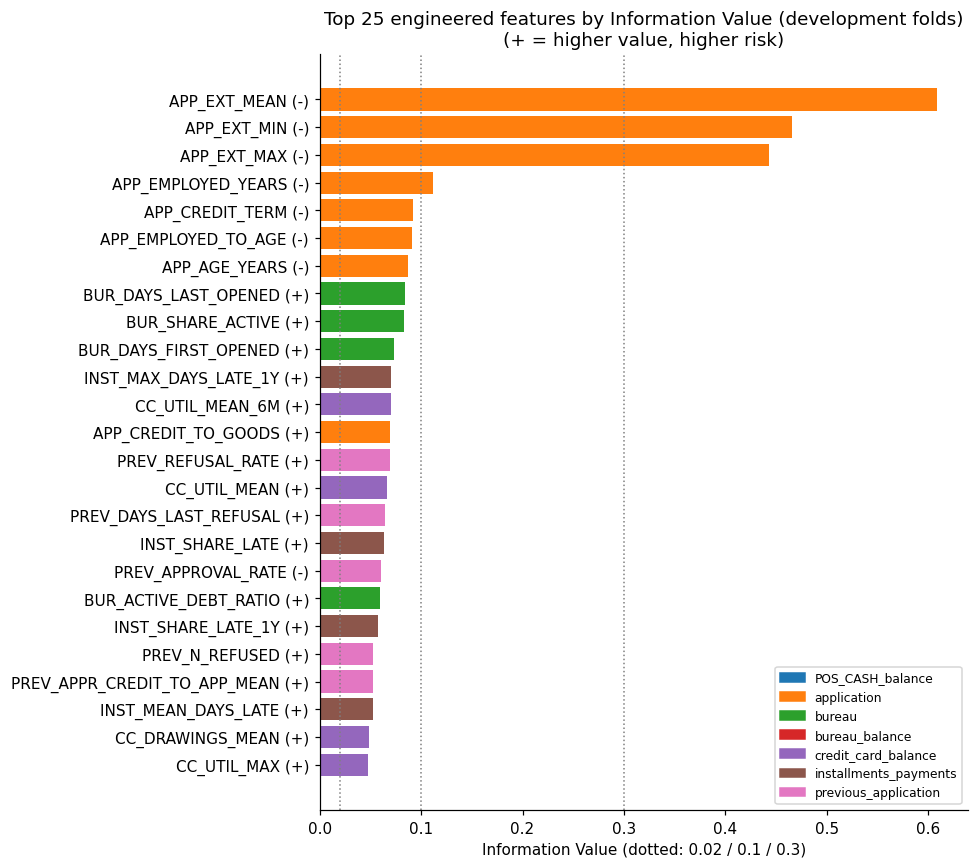

In [5]:
show = ["feature", "source_table", "formula", "direction", "auc", "iv", "iv_strength", "dev_coverage_pct",
        "psi_dev_vs_scoring"]
display(cat[show].head(25).round(4))

top = cat.head(25).iloc[::-1]
palette = dict(zip(sorted(cat.source_table.unique()), plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.feature + " (" + top.direction + ")", top.iv, color=top.source_table.map(palette))
for lim, lab in [(.02, "weak"), (.1, "medium"), (.3, "strong")]:
    ax.axvline(lim, ls=":", c="grey", lw=1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), fontsize=8, loc="lower right")
ax.set(title="Top 25 engineered features by Information Value (development folds)\n(+ = higher value, higher risk)",
       xlabel="Information Value (dotted: 0.02 / 0.1 / 0.3)")
plt.tight_layout(); fig.savefig(FIG / "05_feature_iv_top25.png", bbox_inches="tight"); plt.show()

In [6]:
print("Features with little or no individual signal (IV < 0.02):")
display(cat.loc[cat.iv < .02, ["feature", "source_table", "auc", "iv", "dev_coverage_pct"]].round(4))

Features with little or no individual signal (IV < 0.02):


,feature,source_table,auc,iv,dev_coverage_pct
46,BUR_MAX_OVERDUE_AMT_EVER,bureau,0.5462,0.0196,59.7298
47,BUR_AMT_CREDIT_SUM,bureau,0.5185,0.0190,85.6728
48,PREV_N_REVOLVING,previous_application,0.5379,0.0188,100.0000
49,PREV_N_APPROVED,previous_application,0.5233,0.0184,100.0000
50,POS_SHARE_MONTHS_DPD,POS_CASH_balance,0.5256,0.0178,94.1254
51,PREV_AMT_APPLICATION_MEAN,previous_application,0.5301,0.0177,94.6307
52,X_BUR_DEBT_TO_INCOME,application,0.5420,0.0170,67.1726
53,BUR_ACTIVE_LIMIT_SUM,bureau,0.5220,0.0158,61.3695
54,BUR_ACTIVE_DEBT_SUM,bureau,0.5353,0.0154,67.1726
55,PREV_APPR_DOWN_PAYMENT_RATE_MEAN,previous_application,0.5331,0.0153,88.1959


**Interpretation.**
* **The external-score summaries are the strongest features.** `APP_EXT_MEAN` has the highest IV (0.6091) and ROC-AUC (0.7165).
  An IV above 0.5 calls for a leakage check by convention. This feature is a row mean of `EXT_SOURCE_1–3`, which are recorded
  on the application, so it uses no information from after the decision. Its strength is the combined strength of three
  external scores, and so is its risk: their provenance is undocumented (Step 3). Step 7 tests whether the summaries add
  anything beyond the raw scores.
* **The strongest history features are individually weak**, with IV between 0.06 and 0.08: bureau activity and recency
  (`BUR_DAYS_LAST_OPENED`, `BUR_SHARE_ACTIVE`), recent instalment lateness (`INST_MAX_DAYS_LATE_1Y`), recent card utilisation
  (`CC_UTIL_MEAN_6M`) and prior refusals (`PREV_REFUSAL_RATE`). This is typical of behavioural variables; Section 13.4
  measures their combined value.
* **57 of 103 engineered features have IV < 0.02 on their own.** Low individual IV does not make a feature useless. It can
  matter through interactions, or within the subgroup that has the history (card features cover only 28% of applicants).
  **No feature is dropped here.** Step 7 decides, using model-based importance computed on the training folds.
* **Directions match credit logic.** Older applicants, longer employment and higher external scores go with lower risk. More
  refusals, higher utilisation, more lateness and more recently opened bureau credit go with higher risk.

### 13.3 Recent versus all-time behaviour
Step 3 found that the *severity* of past lateness was not monotonic: 90+ days late was less risky than 31–90 days. The
hypothesis was that old, resolved problems matter less than recent ones. Each pair below is compared **on the same applicants**
(rows where both versions exist), fold by fold.

In [7]:
pairs = [("INST_SHARE_LATE", "INST_SHARE_LATE_1Y"), ("INST_MAX_DAYS_LATE", "INST_MAX_DAYS_LATE_1Y"),
         ("CC_UTIL_MEAN", "CC_UTIL_MEAN_6M"), ("POS_MAX_DPD", "POS_MAX_DPD_12M"),
         ("CC_MAX_DPD", "CC_MAX_DPD_12M"), ("PREV_N_REFUSED", "PREV_N_REFUSED_1Y")]
rows = []
for allt, rec in pairs:
    m = dev[allt].notna() & dev[rec].notna()
    d = dev[m]
    fa = [(auc_dir(g[allt], g.TARGET)[0], auc_dir(g[rec], g.TARGET)[0]) for _, g in d.groupby("fold")]
    rows.append({"all_time": allt, "recent": rec, "common_rows": int(m.sum()),
                 "auc_all_time": auc_dir(d[allt], d.TARGET)[0], "auc_recent": auc_dir(d[rec], d.TARGET)[0],
                 "folds_recent_better": sum(r > a for a, r in fa),
                 "iv_all_time": information_value(dev[allt], dev.TARGET),
                 "iv_recent": information_value(dev[rec], dev.TARGET)})
rec_tab = pd.DataFrame(rows)
rec_tab["auc_gain_recent"] = rec_tab.auc_recent - rec_tab.auc_all_time
display(rec_tab.round(4))

,all_time,recent,common_rows,auc_all_time,auc_recent,folds_recent_better,iv_all_time,iv_recent,auc_gain_recent
0,INST_SHARE_LATE,INST_SHARE_LATE_1Y,173867,0.5667,0.5756,5,0.0636,0.0574,0.0089
1,INST_MAX_DAYS_LATE,INST_MAX_DAYS_LATE_1Y,173846,0.5485,0.5787,5,0.0385,0.0707,0.0302
2,CC_UTIL_MEAN,CC_UTIL_MEAN_6M,54509,0.6474,0.6428,1,0.0659,0.0700,-0.0046
3,POS_MAX_DPD,POS_MAX_DPD_12M,165395,0.5214,0.5213,1,0.0103,0.0001,-0.0001
4,CC_MAX_DPD,CC_MAX_DPD_12M,69683,0.5006,0.5133,5,0.0026,0.0025,0.0127
5,PREV_N_REFUSED,PREV_N_REFUSED_1Y,246008,0.5569,0.5421,0,0.0523,0.0453,-0.0148


all-time max days late          last-12-months max days late         
                             n rate_pct                            n rate_pct
0                       109264     6.79                       124093     6.69
1-7                      59306     8.75                        39534    10.54
8-30                     49571     9.82                         9087    16.29
31-90                     9471    11.42                          961    22.27
90+                       5705     9.57                          171    25.73
no data                  12691     5.98                        72162     7.83

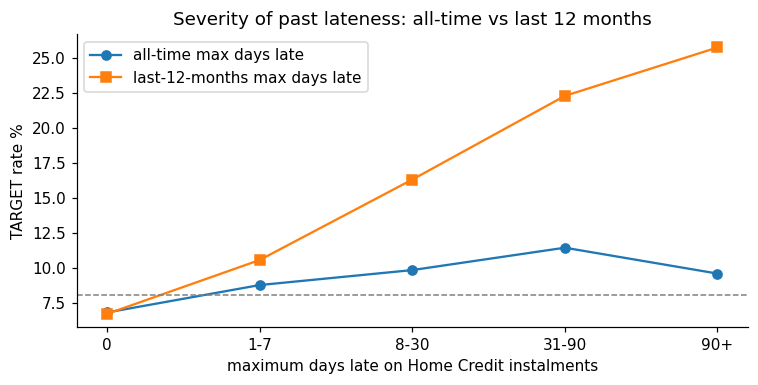

In [8]:
def band_rates(s, edges, labels, missing):
    b = pd.cut(s, edges, labels=labels).astype(object).where(s.notna(), missing)
    g = dev.groupby(b).TARGET.agg(n="size", rate="mean")
    return g.reindex(labels + [missing]).assign(rate_pct=lambda t: (100 * t.rate).round(2)).drop(columns="rate")

edges, labels = [-1, 0, 7, 30, 90, 1e5], ["0", "1-7", "8-30", "31-90", "90+"]
sev = pd.concat({"all-time max days late": band_rates(dev.INST_MAX_DAYS_LATE, edges, labels, "no data"),
                 "last-12-months max days late": band_rates(dev.INST_MAX_DAYS_LATE_1Y, edges, labels, "no data")}, axis=1)
display(sev)

fig, ax = plt.subplots(figsize=(7, 3.6))
for col, mk in [("all-time max days late", "o"), ("last-12-months max days late", "s")]:
    ax.plot(labels, sev[(col, "rate_pct")].loc[labels], marker=mk, label=col)
ax.axhline(100 * dev.TARGET.mean(), ls="--", c="grey", lw=1)
ax.set(xlabel="maximum days late on Home Credit instalments", ylabel="TARGET rate %",
       title="Severity of past lateness: all-time vs last 12 months")
ax.legend(); plt.tight_layout(); fig.savefig(FIG / "05_recency_severity.png", bbox_inches="tight"); plt.show()

**Findings.**
* **For repayment lateness, recent beats all-time.** On the same applicants, `INST_MAX_DAYS_LATE_1Y` ranks risk better than the
  all-time maximum: ROC-AUC 0.5787 versus 0.5485, better in all 5 folds. The recent share of late instalments also beats the all-time
  share (0.5756 versus 0.5667, 5 of 5 folds), and so does recent card delinquency (0.5133 versus 0.5006, 5 of 5).
* **This resolves the Step 3 puzzle.** All-time maximum lateness peaks at 31–90 days (11.42%) and then *falls* for 90+ days
  (9.57%). Restricted to the last 12 months, the curve rises steadily: 10.54% at 1–7 days, then 16.29%, 22.27%, and 25.73% at
  90+ days (n = 171). Severe problems that are old and resolved carry less risk than recent ones.
* **Not every recent version helps.** The 6-month card utilisation is better in only 1 of 5 folds, as is the 12-month POS
  delinquency. Refusals over the whole history rank better than refusals in the last year (0 of 5): a long refusal record is
  more informative than a recent count.

**Decision.** Keep both versions of every pair, and let the models choose in Steps 7–8. Recency windows were the right design
for repayment behaviour.

### 13.4 Does each history table add value? (ablation on identical folds)
Feature sets are compared with the same models and the same five folds:
* **APP-RAW**: the original application columns only, after Step 4's column rules.
* **APP**: APP-RAW plus the engineered application ratios. This is the **baseline** for history tables.
* **APP + one table**: the standalone value of each history table.
* **ALL**: APP + every history table + the cross-table affordability features.
* **ALL − one table**: the *unique* value of each table, given all the others.

Gradient boosting (library defaults, not tuned) is used for every set, because it needs no per-set preprocessing choices.
Logistic Regression (Step 4 variant D, C = 1) is run on APP-RAW, APP and ALL to confirm the main conclusions with a second
model family. These runs measure the **value of the features**; model tuning and selection come in notebook 04.

In [9]:
cols_all = decide_columns(dev)                       # Step 4 rules (same function, same development data)

def block_of(f):
    if f in raw_app:
        return "APP-RAW"
    for p, b in [("APP_", "APP"), ("FLAG_NOT_EMPLOYED", "APP"), ("PREV_", "PREV"), ("HAS_PREV", "PREV"),
                 ("BUR_", "BUREAU"), ("HAS_BUREAU", "BUREAU"), ("POS_", "POS"), ("HAS_POS", "POS"),
                 ("CC_", "CC"), ("HAS_CC", "CC"), ("INST_", "INST"), ("HAS_INST", "INST"), ("X_", "CROSS"),
                 ("BB_", "BB")]:
        if f.startswith(p):
            return b
    return "OTHER"

usable = {c for k, v in cols_all.items() if k != "audit" for c in v}
blocks = pd.Series({f: block_of(f) for f in usable})
display(blocks.value_counts().to_frame("usable features"))
HIST = ["PREV", "BUREAU", "POS", "CC", "INST"]

def subset(allowed):
    return {k: [c for c in v if c in allowed] for k, v in cols_all.items() if k != "audit"}

def members(*bl):
    return set(blocks[blocks.isin(bl)].index)

configs = {"APP-RAW": members("APP-RAW"), "APP": members("APP-RAW", "APP")}
for h in HIST:
    configs[f"APP + {h}"] = members("APP-RAW", "APP", h)
configs["ALL"] = members("APP-RAW", "APP", "CROSS", *HIST)
for h in HIST:
    configs[f"ALL - {h}"] = configs["ALL"] - members(h)
print({k: len(v) for k, v in configs.items()})

,usable features
APP-RAW,86
PREV,22
BUREAU,21
APP,15
INST,13
CC,12
POS,11
CROSS,1


{'APP-RAW': 86, 'APP': 101, 'APP + PREV': 123, 'APP + BUREAU': 122, 'APP + POS': 112, 'APP + CC': 113, 'APP + INST': 114, 'ALL': 181, 'ALL - PREV': 159, 'ALL - BUREAU': 160, 'ALL - POS': 170, 'ALL - CC': 169, 'ALL - INST': 168}


In [10]:
def run_cv(make_pipe, sub, label, model):
    out = []
    for k, (tri, vai) in enumerate(folds):
        t = time.time()
        pipe = make_pipe(sub).fit(dev.iloc[tri], y_dev[tri])
        p = pipe.predict_proba(dev.iloc[vai])[:, 1]
        out.append({"model": model, "feature_set": label, "fold": k, "n_features": len(set().union(*sub.values())),
                    "roc_auc": roc_auc_score(y_dev[vai], p), "pr_auc": average_precision_score(y_dev[vai], p),
                    "seconds": time.time() - t})
        del pipe
    release_memory()
    return out

hgb = lambda sub: Pipeline([("prep", tree_preprocessor(sub)), ("m", HistGradientBoostingClassifier(
    categorical_features=tree_categorical_mask(sub), random_state=SEED))])
lr = lambda sub: Pipeline([("prep", lr_preprocessor(sub, clip=True, log=True, bins=True)),
                           ("m", LogisticRegression(C=1.0, max_iter=3000))])

t0 = time.time()
res = []
for label, allowed in configs.items():
    res += run_cv(hgb, subset(allowed), label, "HistGradientBoosting")
    print(f"HGB {label:14s} done ({time.time() - t0:5.0f}s)", flush=True)
for label in ["APP-RAW", "APP", "ALL"]:
    res += run_cv(lr, subset(configs[label]), label, "LogisticRegression")
    print(f"LR  {label:14s} done ({time.time() - t0:5.0f}s)", flush=True)
abl = pd.DataFrame(res)
abl.to_csv(REPORTS / "step5_ablation_cv.csv", index=False)

HGB APP-RAW        done (   57s)


HGB APP            done (  126s)


HGB APP + PREV     done (  215s)


HGB APP + BUREAU   done (  302s)


HGB APP + POS      done (  379s)


...

HGB ALL - CC       done ( 1167s)


HGB ALL - INST     done ( 1303s)


LR  APP-RAW        done ( 1352s)


LR  APP            done ( 1427s)


LR  ALL            done ( 1540s)


In [11]:
def summarise(model, ref):
    d = abl[abl.model == model]
    base = d[d.feature_set == ref].set_index("fold")
    rows = []
    for fs, g in d.groupby("feature_set", sort=False):
        g = g.set_index("fold")
        diff = g.roc_auc - base.roc_auc
        rows.append({"feature_set": fs, "n_features": g.n_features.iloc[0], "roc_auc": g.roc_auc.mean(),
                     "roc_auc_std": g.roc_auc.std(), "pr_auc": g.pr_auc.mean(),
                     f"auc_vs_{ref}": diff.mean(), f"folds_better_than_{ref}": int((diff > 0).sum()),
                     "fit_seconds": g.seconds.mean()})
    return pd.DataFrame(rows).set_index("feature_set")

hgb_sum = summarise("HistGradientBoosting", "APP")
all_ref = abl[(abl.model == "HistGradientBoosting") & (abl.feature_set == "ALL")].set_index("fold").roc_auc
hgb_sum["auc_loss_when_removed_from_ALL"] = [
    (all_ref - abl[(abl.model == "HistGradientBoosting") & (abl.feature_set == fs)].set_index("fold").roc_auc).mean()
    if fs.startswith("ALL - ") else np.nan for fs in hgb_sum.index]
print("Gradient boosting (defaults), 5 development folds:")
display(hgb_sum.round(4))
print("Logistic Regression (Step 4 variant D), 5 development folds:")
display(summarise("LogisticRegression", "APP").round(4))

Gradient boosting (defaults), 5 development folds:


,n_features,roc_auc,roc_auc_std,pr_auc,auc_vs_APP,folds_better_than_APP,fit_seconds,auc_loss_when_removed_from_ALL
feature_set,,,,,,,,
APP-RAW,86,0.7516,0.0027,0.2338,-0.0063,0,11.3145,NaN
APP,101,0.7579,0.0019,0.2392,0.0000,0,13.9114,NaN
APP + PREV,123,0.7639,0.0017,0.2473,0.0061,5,17.6093,NaN
APP + BUREAU,122,0.7637,0.0014,0.2470,0.0058,5,17.4339,NaN
APP + POS,112,0.7626,0.0023,0.2447,0.0047,5,15.4629,NaN
APP + CC,113,0.7612,0.0020,0.2442,0.0033,5,14.8095,NaN
APP + INST,114,0.7639,0.0024,0.2464,0.0060,5,14.5377,NaN
ALL,181,0.7795,0.0027,0.2668,0.0216,5,26.7055,NaN
ALL - PREV,159,0.7766,0.0023,0.2615,0.0187,5,23.4735,0.0029


Logistic Regression (Step 4 variant D), 5 development folds:


,n_features,roc_auc,roc_auc_std,pr_auc,auc_vs_APP,folds_better_than_APP,fit_seconds
feature_set,,,,,,,
APP-RAW,86,0.7427,0.0024,0.2211,-0.0111,0,9.6365
APP,101,0.7537,0.0017,0.2360,0.0000,0,15.1375
ALL,181,0.7779,0.0028,0.2654,0.0242,5,22.5620


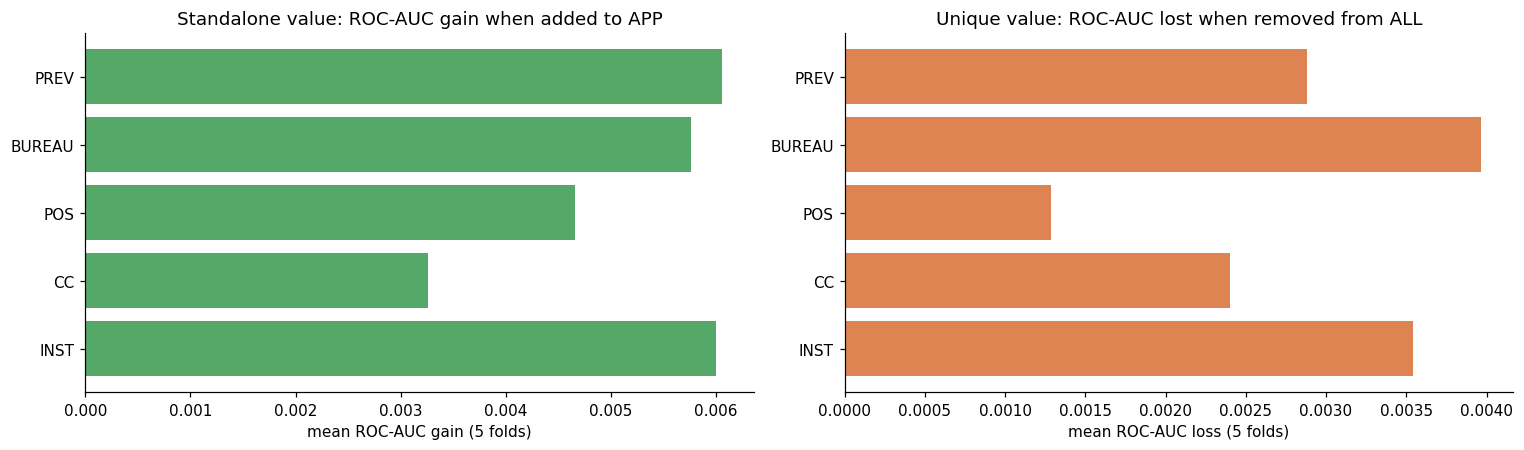

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
add = hgb_sum.loc[[f"APP + {h}" for h in HIST], "auc_vs_APP"]
rem = hgb_sum.loc[[f"ALL - {h}" for h in HIST], "auc_loss_when_removed_from_ALL"]
ax[0].barh([h for h in HIST], add, color="#55A868")
ax[0].set(title="Standalone value: ROC-AUC gain when added to APP", xlabel="mean ROC-AUC gain (5 folds)")
ax[1].barh([h for h in HIST], rem, color="#DD8452")
ax[1].set(title="Unique value: ROC-AUC lost when removed from ALL", xlabel="mean ROC-AUC loss (5 folds)")
for a in ax:
    a.axvline(0, c="grey", lw=1); a.invert_yaxis()
plt.tight_layout(); fig.savefig(FIG / "05_history_block_value.png", bbox_inches="tight"); plt.show()

**Findings** (5 folds; every comparison is paired on identical folds).
* **The history tables add substantial value.** With gradient boosting, ROC-AUC goes from 0.7579 for the application data (APP)
  to 0.7795 with everything (ALL), a gain of 0.0216. With Logistic Regression it goes from 0.7537 to 0.7779 (+0.0242). Both
  improve in all 5 folds. PR-AUC, which focuses on the risky minority, rises from 0.2392 to 0.2668 with gradient boosting.
* **The engineered application ratios help too.** Moving from the raw application columns to APP adds 0.0063 with gradient
  boosting and 0.0111 with Logistic Regression.
* **Every table has standalone value.** Added alone to APP, each improves all 5 folds: previous applications +0.0061,
  instalments +0.0060, bureau +0.0058, POS +0.0047, credit cards +0.0033.
* **Every table has unique value.** Removing any one table from ALL lowers ROC-AUC: bureau by 0.0040, instalments 0.0035,
  previous applications 0.0029, credit cards 0.0024, POS 0.0013. The tables overlap, since their standalone gains add up
  to 0.0259 (more than the combined 0.0216), but none is redundant.

**Decision.** Keep all five history tables. On the full feature set, untuned gradient boosting and the reference Logistic
Regression reach similar ROC-AUC (0.7795 versus 0.7779). The real model comparison, after tuning, is Step 8.

### 13.5 Stability between training and scoring data
A feature that ranks risk well in training is only useful if it looks the same when new applications are scored.
PSI compares the development distribution of each engineered feature with the scoring set (`application_test`).

In [13]:
print("PSI classes:", cat.stability.value_counts().sort_index().to_dict())
display(cat.sort_values("psi_dev_vs_scoring", ascending=False)
        [["feature", "source_table", "psi_dev_vs_scoring", "stability", "dev_coverage_pct", "scoring_coverage_pct", "iv"]]
        .head(12).round(3))
bb = pd.DataFrame({f: {"dev_coverage_pct": 100 * dev[f].notna().mean(), "scoring_coverage_pct": 100 * score[f].notna().mean(),
                       "psi": psi(dev[f], score[f])} for f in DRIFT_RISK if f in dev.columns and f != "HAS_BUREAU_BALANCE"}).T
print("Drift-risk features excluded by default (for comparison):")
display(bb.round(3))

PSI classes: {'stable': 93, 'moderate shift': 1, 'major shift': 9}


,feature,source_table,psi_dev_vs_scoring,stability,dev_coverage_pct,scoring_coverage_pct,iv
100,HAS_BUREAU_BALANCE,bureau_balance,1.554,major shift,100.000,100.000,0.000
60,BB_SHARE_MONTHS_DPD,bureau_balance,1.415,major shift,29.163,83.943,0.013
73,BB_WORST_STATUS,bureau_balance,1.412,major shift,29.163,83.943,0.010
4,APP_CREDIT_TERM,application,1.165,major shift,99.996,99.951,0.091
64,BB_WORST_STATUS_12M,bureau_balance,1.073,major shift,23.871,72.856,0.012
81,BUR_ACTIVE_ANNUITY_SUM,bureau,0.982,major shift,19.917,64.377,0.006
97,BB_N_MONTHS_KNOWN,bureau_balance,0.882,major shift,100.000,100.000,0.000
42,APP_N_DOCUMENTS,application,0.299,major shift,100.000,100.000,0.022
79,X_TOTAL_ANNUITY_TO_INCOME,application,0.280,major shift,99.996,99.951,0.006
69,APP_CREDIT_TO_INCOME,application,0.114,moderate shift,100.000,100.000,0.011


Drift-risk features excluded by default (for comparison):


,dev_coverage_pct,scoring_coverage_pct,psi
BB_N_MONTHS_KNOWN,100.000,100.000,0.882
BB_WORST_STATUS,29.163,83.943,1.412
BB_WORST_STATUS_12M,23.871,72.856,1.073
BB_SHARE_MONTHS_DPD,29.163,83.943,1.415
BUR_ACTIVE_ANNUITY_SUM,19.917,64.377,0.982
X_TOTAL_ANNUITY_TO_INCOME,99.996,99.951,0.280


**Findings.**
* **Most features are stable.** 93 of 103 engineered features have PSI < 0.1. One shows a moderate shift (`APP_CREDIT_TO_INCOME`,
  0.114) and nine a major shift.
* **Seven of the nine major shifts are the drift-risk features already excluded by default.** After the Step 5 fix,
  `BUR_ACTIVE_ANNUITY_SUM` shows its true coverage, 19.917% of development versus 64.377% of scoring applicants, instead of hiding the
  gap behind zeros.
* **Two included features shift strongly.** `APP_CREDIT_TERM` (PSI 1.165) has shorter implied terms in the scoring set, and
  `APP_N_DOCUMENTS` has a PSI of 0.299. `APP_CREDIT_TERM` also has the fifth-highest IV among engineered features (0.0915),
  so it is both valuable and unstable.

**Decision.** Keep both, compare models with and without them in Step 9, and put both on the monitoring list.

### 13.6 Step 5 summary

| Question | Evidence | Decision |
|---|---|---|
| Built only from information available at decision time? | All checks pass; post-application bureau updates are excluded in the build | — |
| Correct granularity? | One row per applicant; every table is aggregated before joining | — |
| Data-quality issues in the engineered features? | Sums over all-missing amounts were 0 instead of missing (found through PSI) | Fixed (`min_count=1`); dataset rebuilt; notebook 02 re-run |
| Recent versus all-time behaviour | Recent repayment lateness ranks risk better, and its severity curve becomes monotonic; not true for utilisation, POS delinquency or refusals | Keep both versions |
| Do the history tables add value? | +0.0216 (gradient boosting) / +0.0242 (Logistic Regression) ROC-AUC, all 5 folds; every table contributes uniquely | Keep all tables |
| Individual strength | External-score summaries strongest; 57 features have IV < 0.02 on their own | Feature selection in Step 7 |
| Stability on scoring data | 7 drift-risk features (excluded) and 2 included features shift strongly | Step 9 robustness test; monitoring |

**Stage status.** Step 5 is complete. Next is notebook 04: Steps 6–9 (validation recap, feature selection and imbalance
handling, modelling, evaluation).